In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import sys
sys.path.append("../../../SRC/")

### Define Parameters and preprocess the data

In [2]:
from DDG_ANALYSIS.B_PREPROCESS import preprocess

# --- Dictionary mapping file names to their json file paths ---
files = {
    "MIN": "../../../A_MODELS/FUSION/DDG/A_OUTPUT/ddG_ridge_LOO_pred&error_MIN_MET_OFF.json",
    "MAX": "../../../A_MODELS/FUSION/DDG/A_OUTPUT/ddG_ridge_LOO_pred&error_MAX_MET_OFF.json",
    "AVG": "../../../A_MODELS/FUSION/DDG/A_OUTPUT/ddG_ridge_LOO_pred&error_AVG_MET_OFF.json",
    "MET": "../../../A_MODELS/Z_META/DDG/RANDOM/ddG_ridge_LOO_pred&error.json",
    "OFF": "../../../A_MODELS/FEP/DDG/OFF/OFF_RANDOM_ddG_FROM_FEP_GRAPH_pred&error.json"
}

DISPLAY_ORDER = ["OFF","MET","AVG","MAX","MIN"]
DISPLAY_ORDER.reverse()
ALPHA = 0.01
TARGETS_TO_SKIP = ("galectin","thrombin","p2")
METRICS = ["rmse", "kendalls_tau", "window_tau", "slope_diff"]

results_all, bad_splits = preprocess(files, TARGETS_TO_SKIP)


No splits removed.


In [3]:
# Check which splits have constant labels or predictions
print(bad_splits)

{}


### Friedman ANOVA

In [4]:
from DDG_ANALYSIS.C_FRIEDMAN_ANOVA import run_friedman

friedman_results = run_friedman(results_all, METRICS, TARGETS_TO_SKIP=TARGETS_TO_SKIP)
print(friedman_results)

{'rmse': {'bace': {'statistic': 193.904, 'p_value': 7.67882373188712e-41}, 'cdk2': {'statistic': 211.88743718592963, 'p_value': 1.0432368133028586e-44}, 'cdk8': {'statistic': 205.84000000000015, 'p_value': 2.085024010696919e-43}, 'cmet': {'statistic': 168.83366733466943, 'p_value': 1.8611373593546612e-35}, 'eg5': {'statistic': 215.952, 'p_value': 1.3929960500612663e-45}, 'hif2a': {'statistic': 330.3600000000001, 'p_value': 3.046605584726097e-70}, 'hunt': {'statistic': 123.36799999999994, 'p_value': 1.0189101304779196e-25}, 'jnk1': {'statistic': 204.41025641025638, 'p_value': 4.232315900046444e-43}, 'mcl1': {'statistic': 336.77599999999984, 'p_value': 1.2557506785892207e-71}, 'p38': {'statistic': 92.63200000000006, 'p_value': 3.6326603969710644e-19}, 'pde10': {'statistic': 297.9920000000002, 'p_value': 2.937237417533111e-63}, 'pde2': {'statistic': 250.8525252525253, 'p_value': 4.264847979133624e-53}, 'pfkfb3': {'statistic': 202.4960000000001, 'p_value': 1.0919609761734669e-42}, 'ptp1b':

### Wilcoxon test

In [5]:
from DDG_ANALYSIS.D_WILCOXON import compute_wilcox_posthoc
wilcox_posthoc_results = compute_wilcox_posthoc(results_all, metrics=METRICS, targets_to_skip=TARGETS_TO_SKIP)


### Significance plot

rmse significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/CONSENSUS_FEP/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


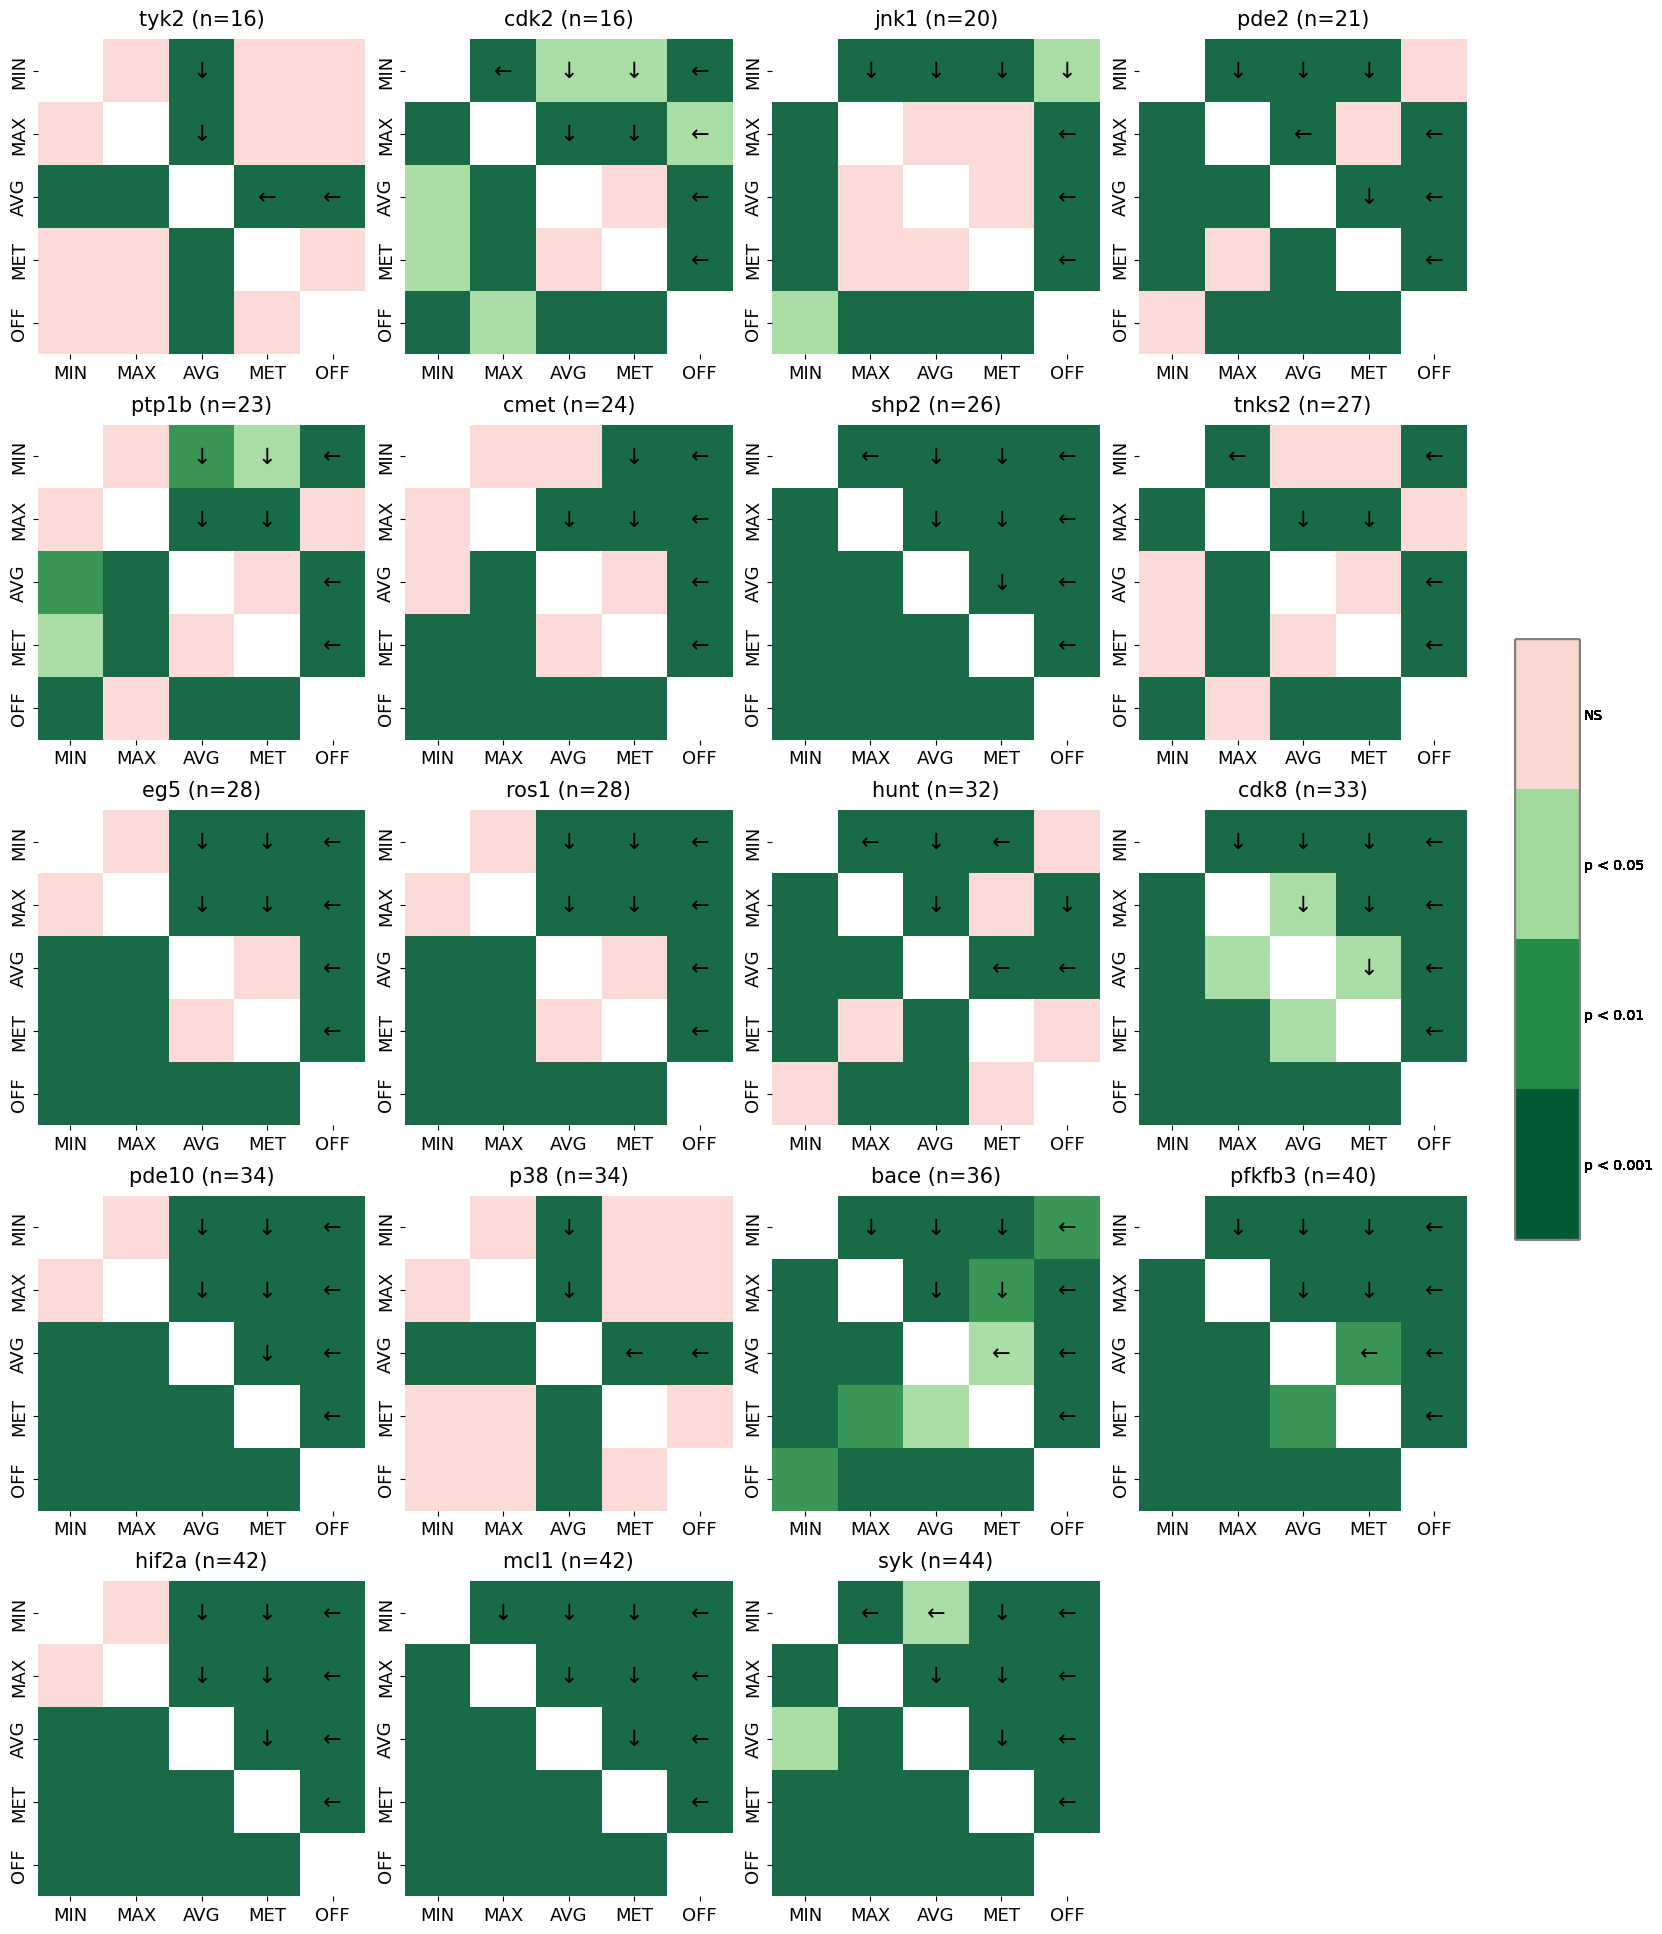

kendalls_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/CONSENSUS_FEP/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


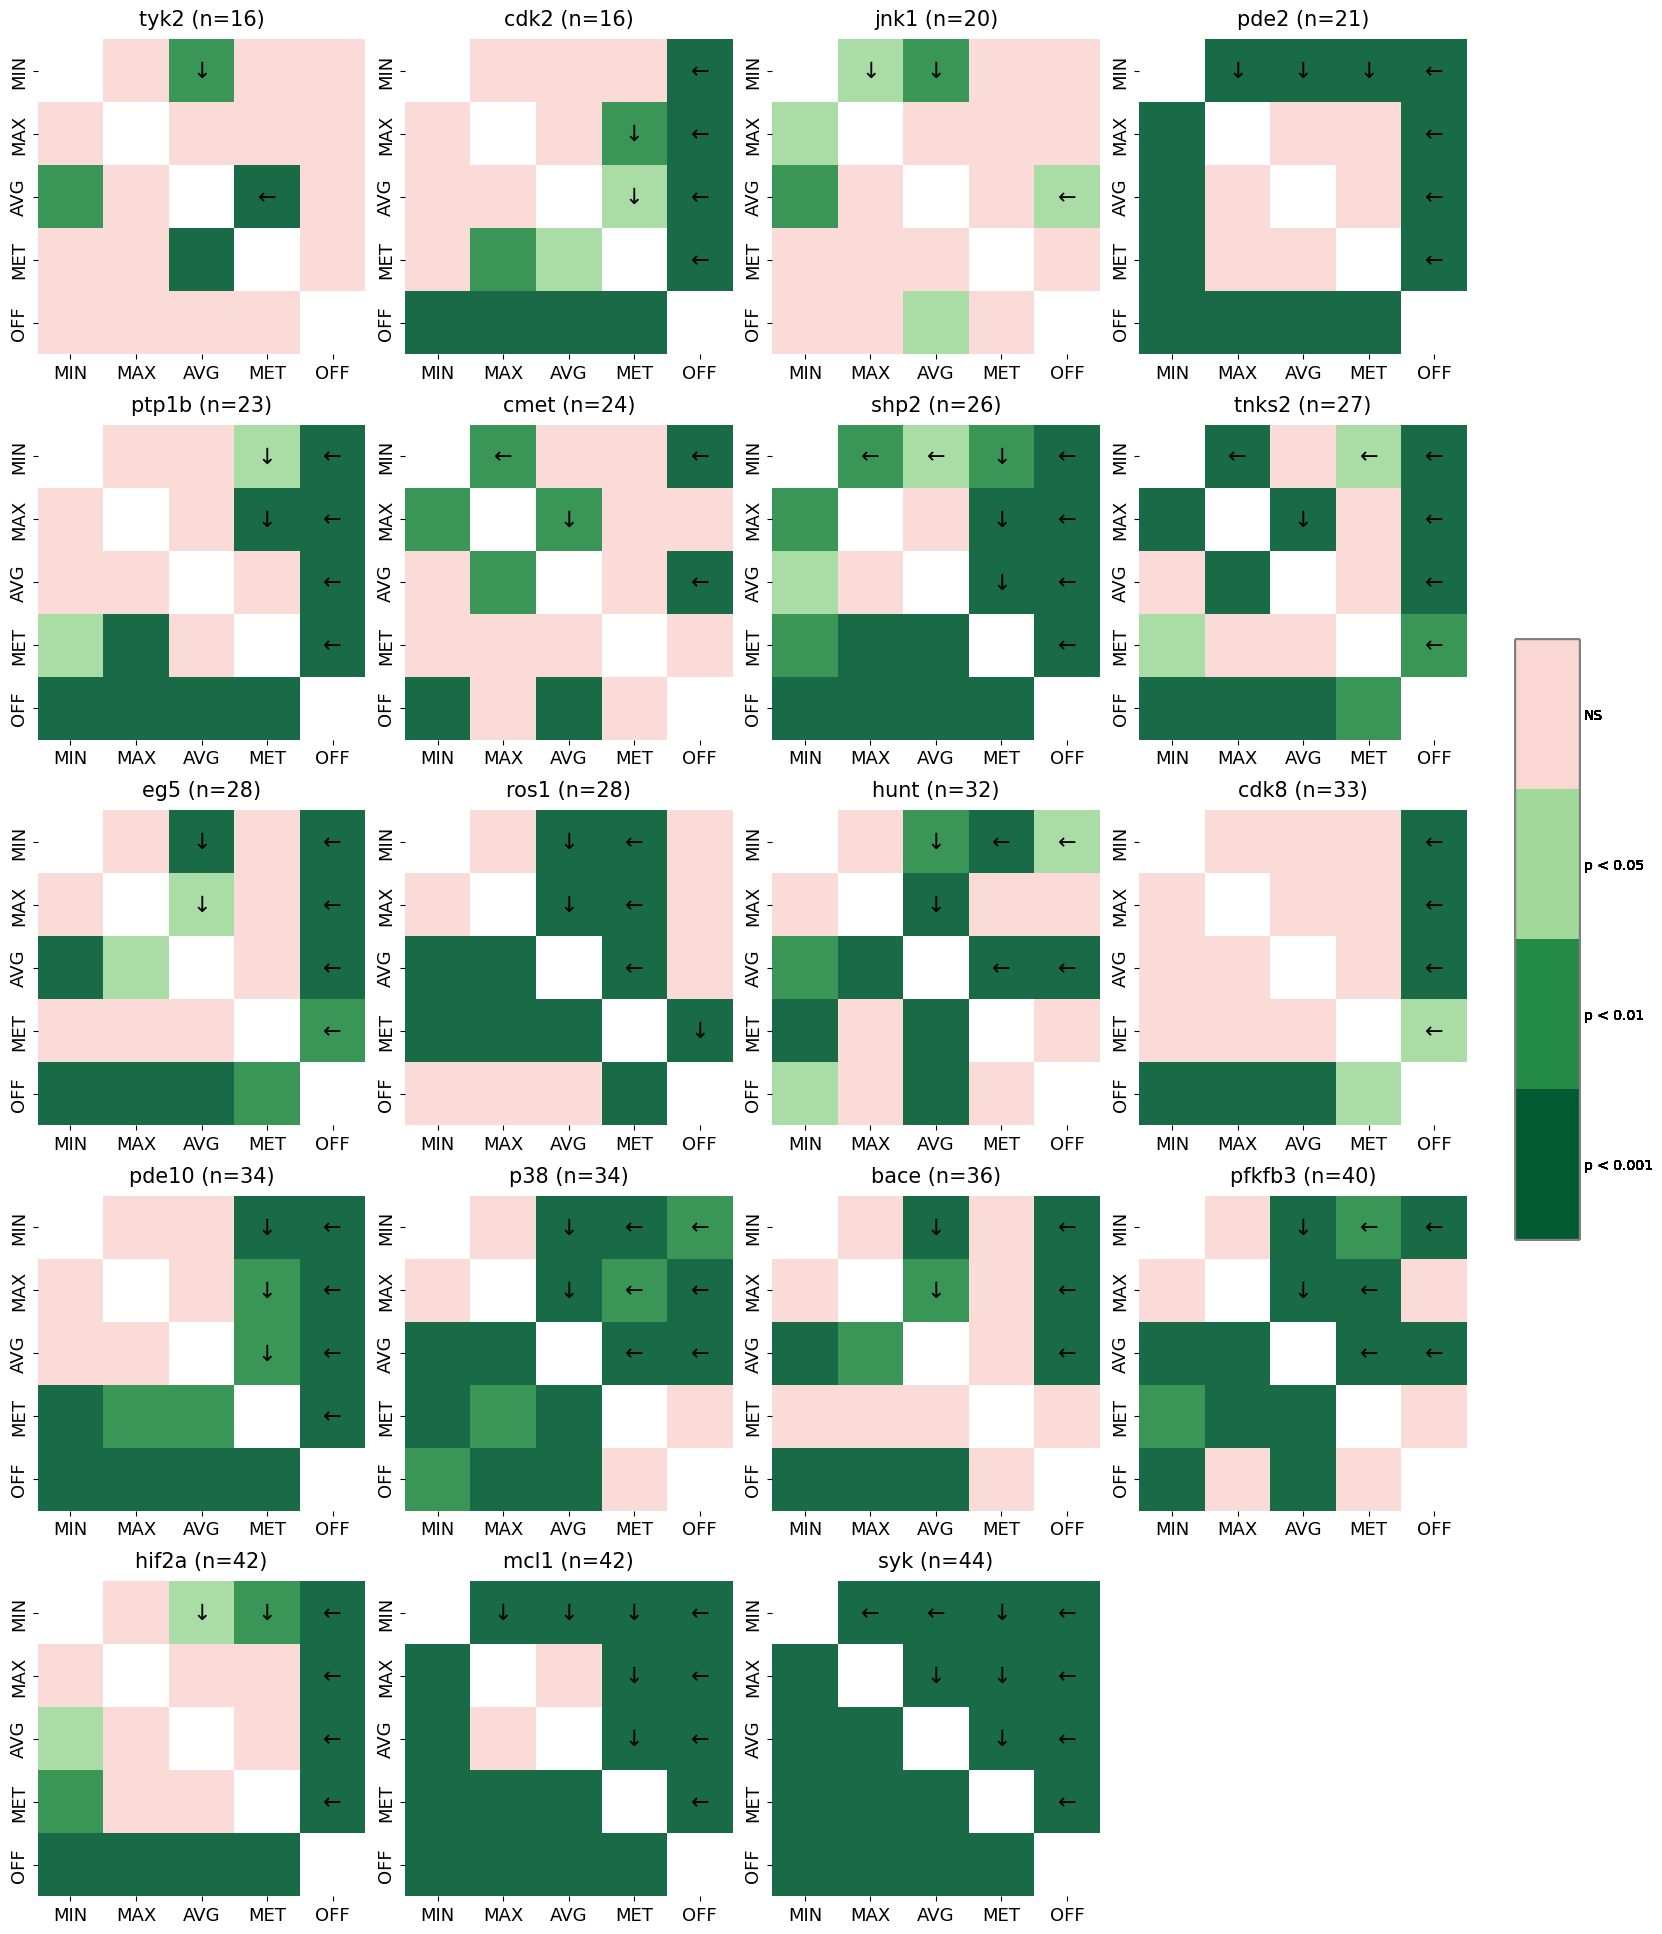

window_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/CONSENSUS_FEP/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


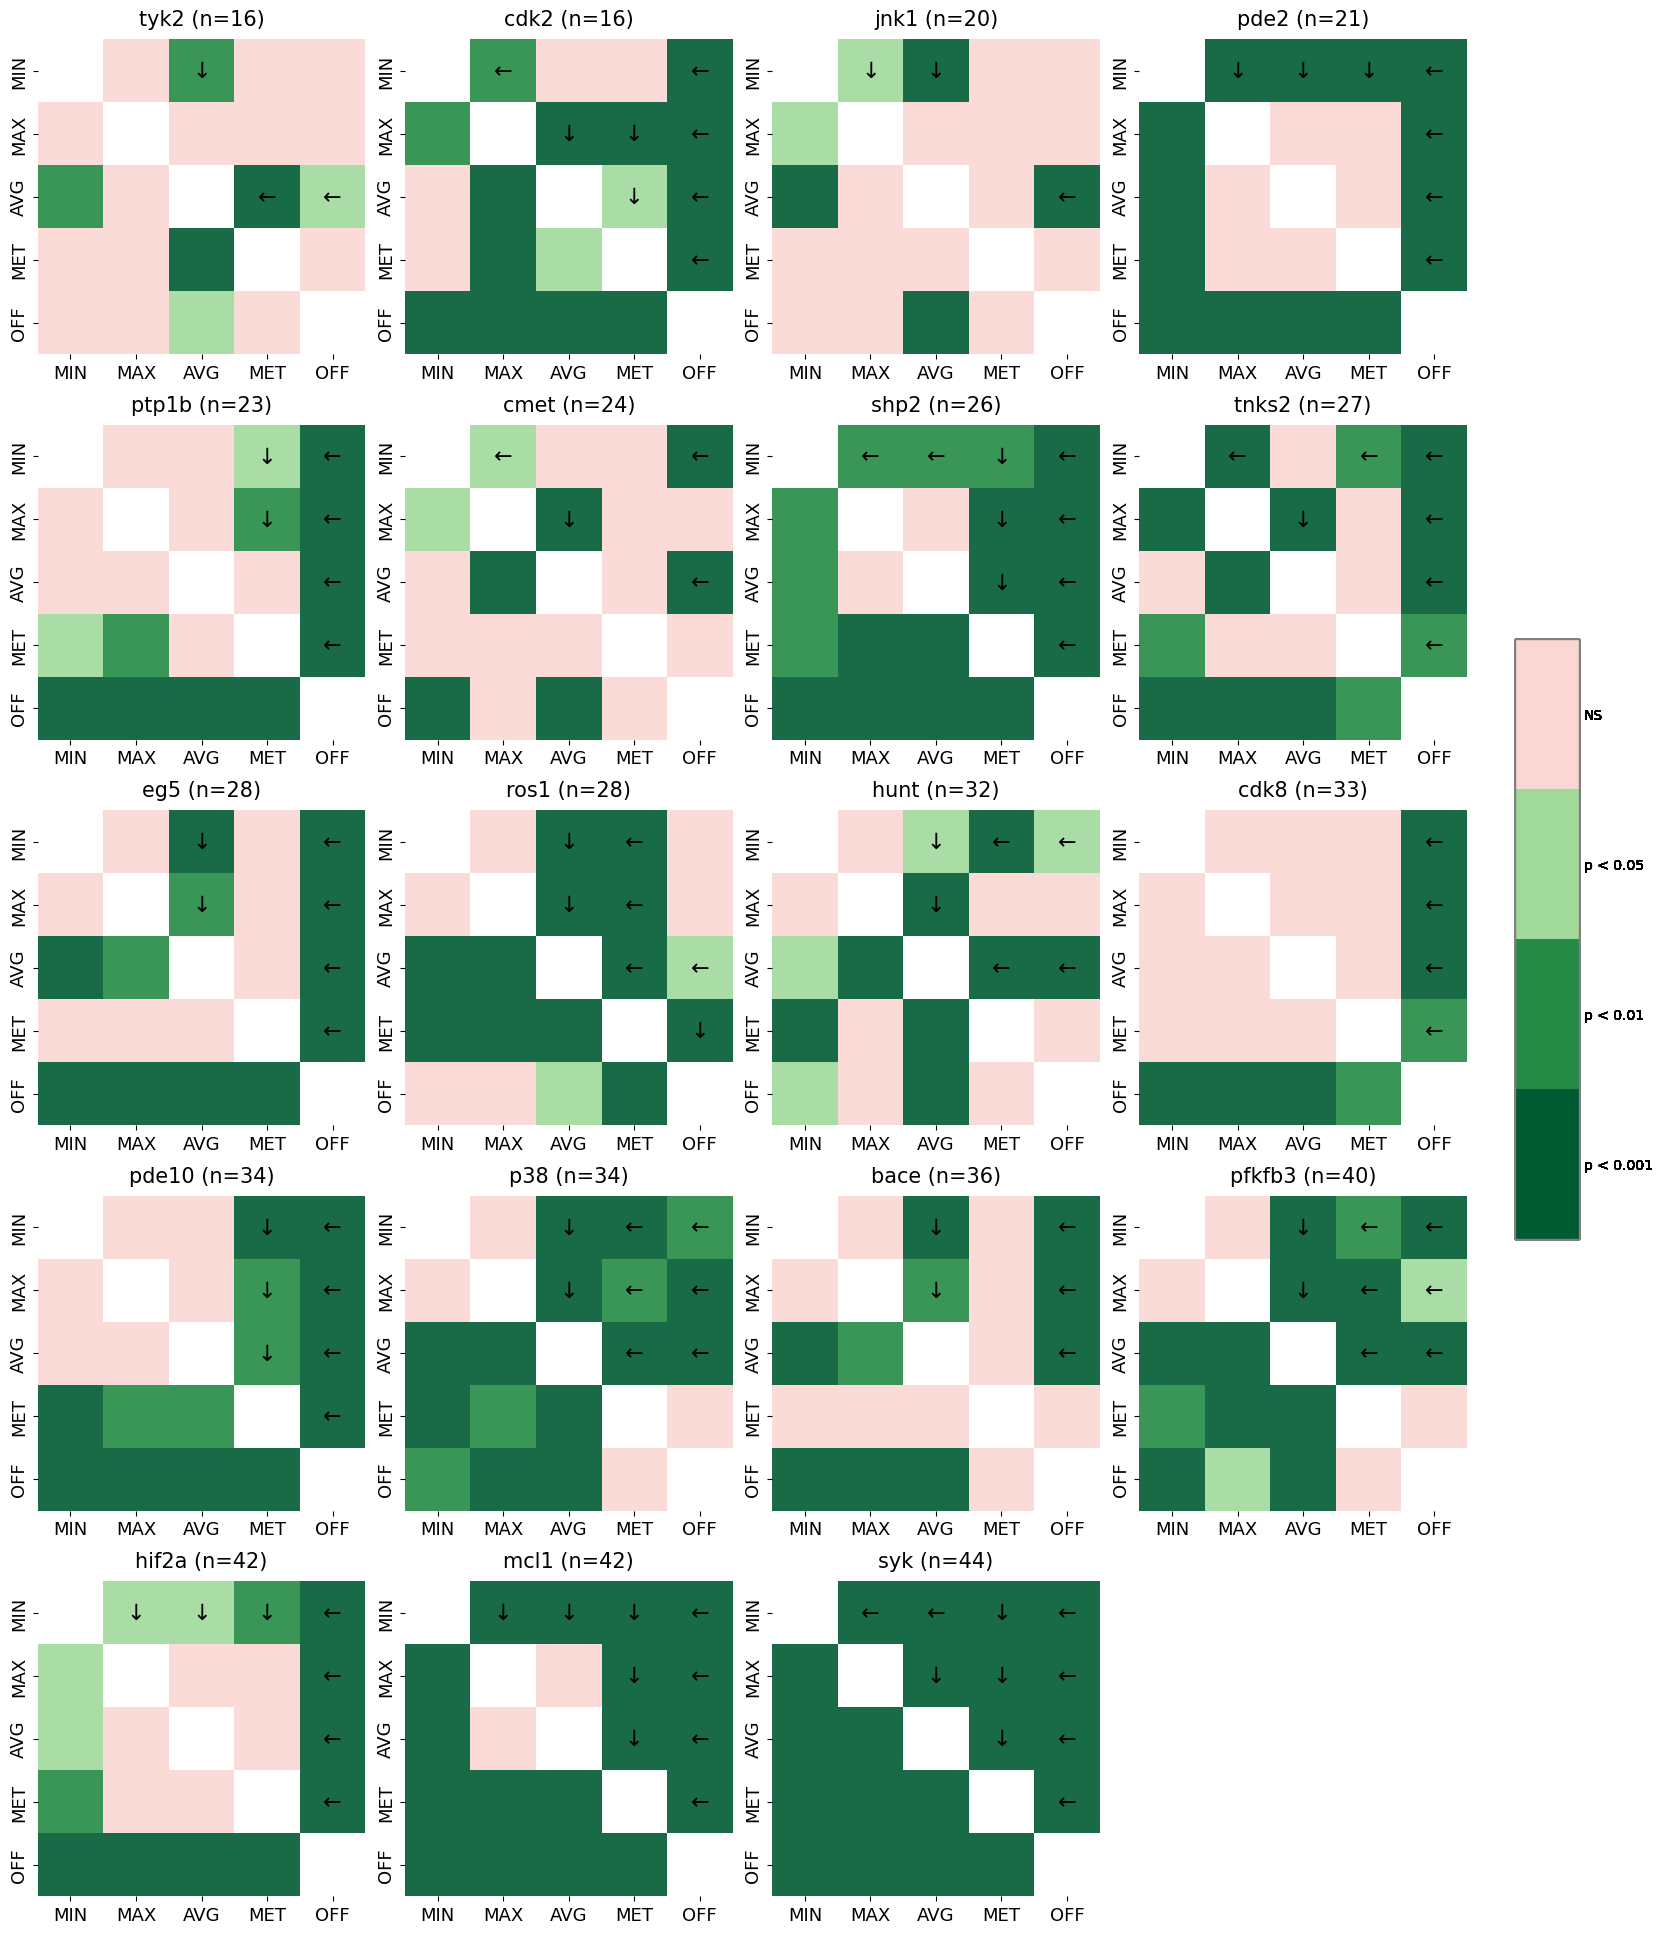

slope_diff significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/CONSENSUS_FEP/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


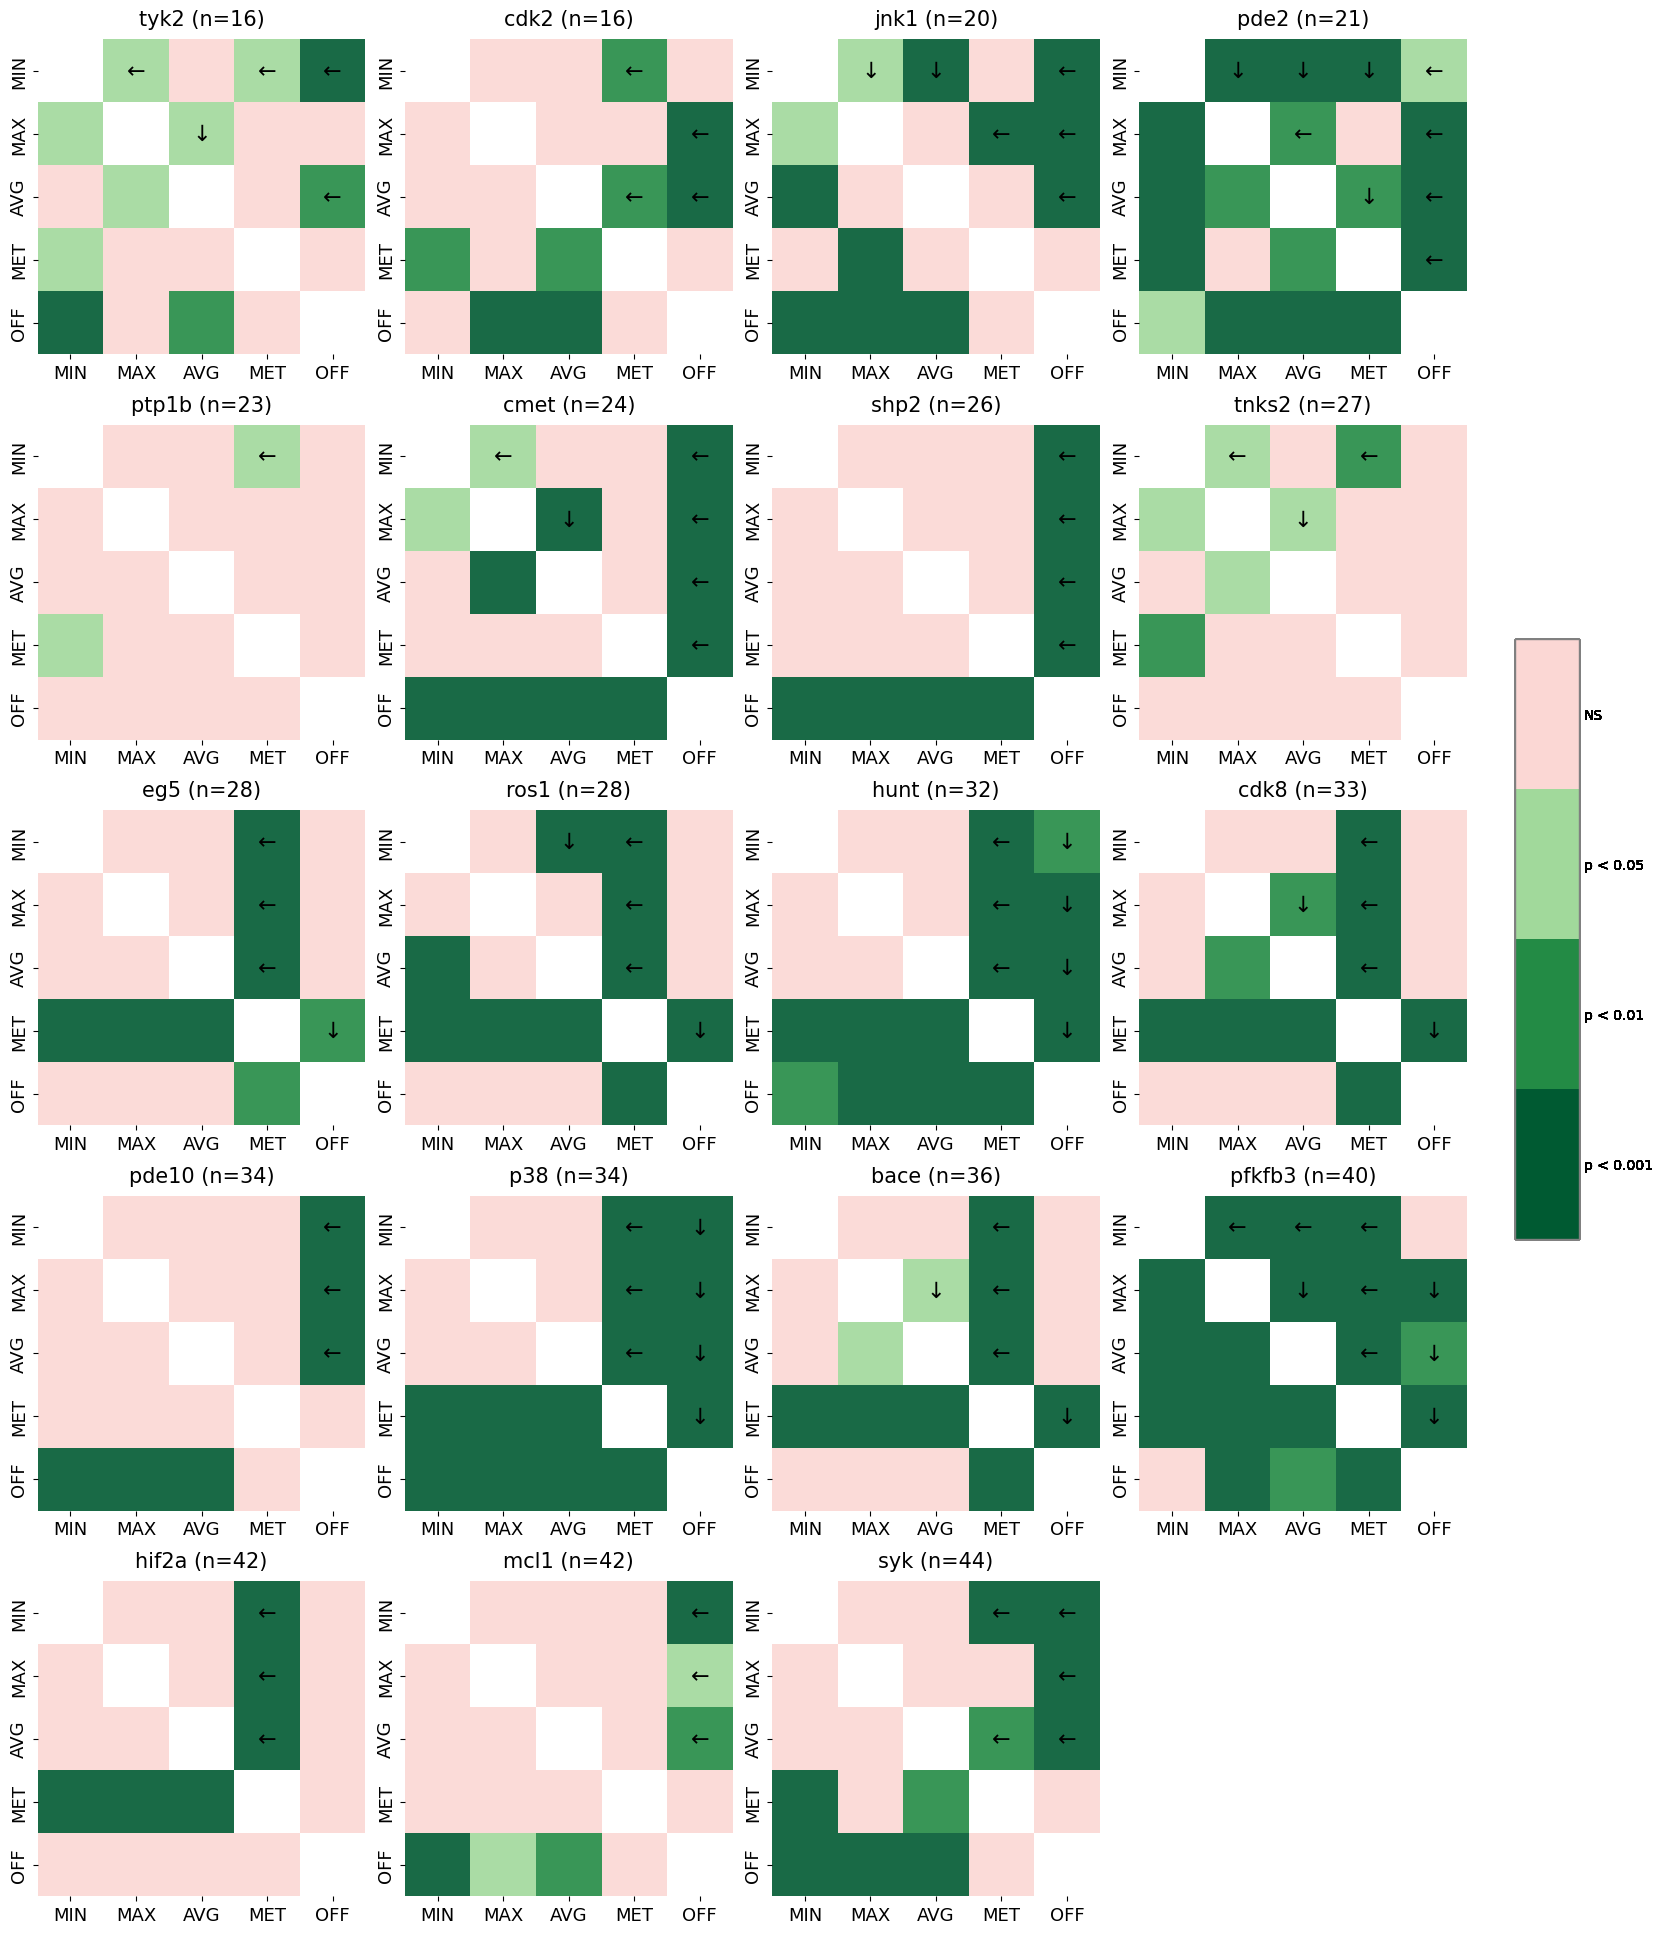

In [6]:
from DDG_ANALYSIS.D_WILCOXON import sign_plot
sign_plot(
    results_all,
    wilcox_posthoc_results,
    DISPLAY_ORDER,
    target_counts_path= "../../../0_DATA/N_COMPOUNDS_PER_TARGET.json",
    metrics=METRICS,
    targets_to_skip=TARGETS_TO_SKIP,
    n_cols=4,
    arrow_threshold=0.05, # This is the p value for an arrow to show, should be in accordance with the legend (green -> has an arrow)
    alpha=0.9, # this alpha is how seethrough plot is, not to be mixed up with ALPHA (p value)
)

### Effect size & Significance (Based on wilcoxon)

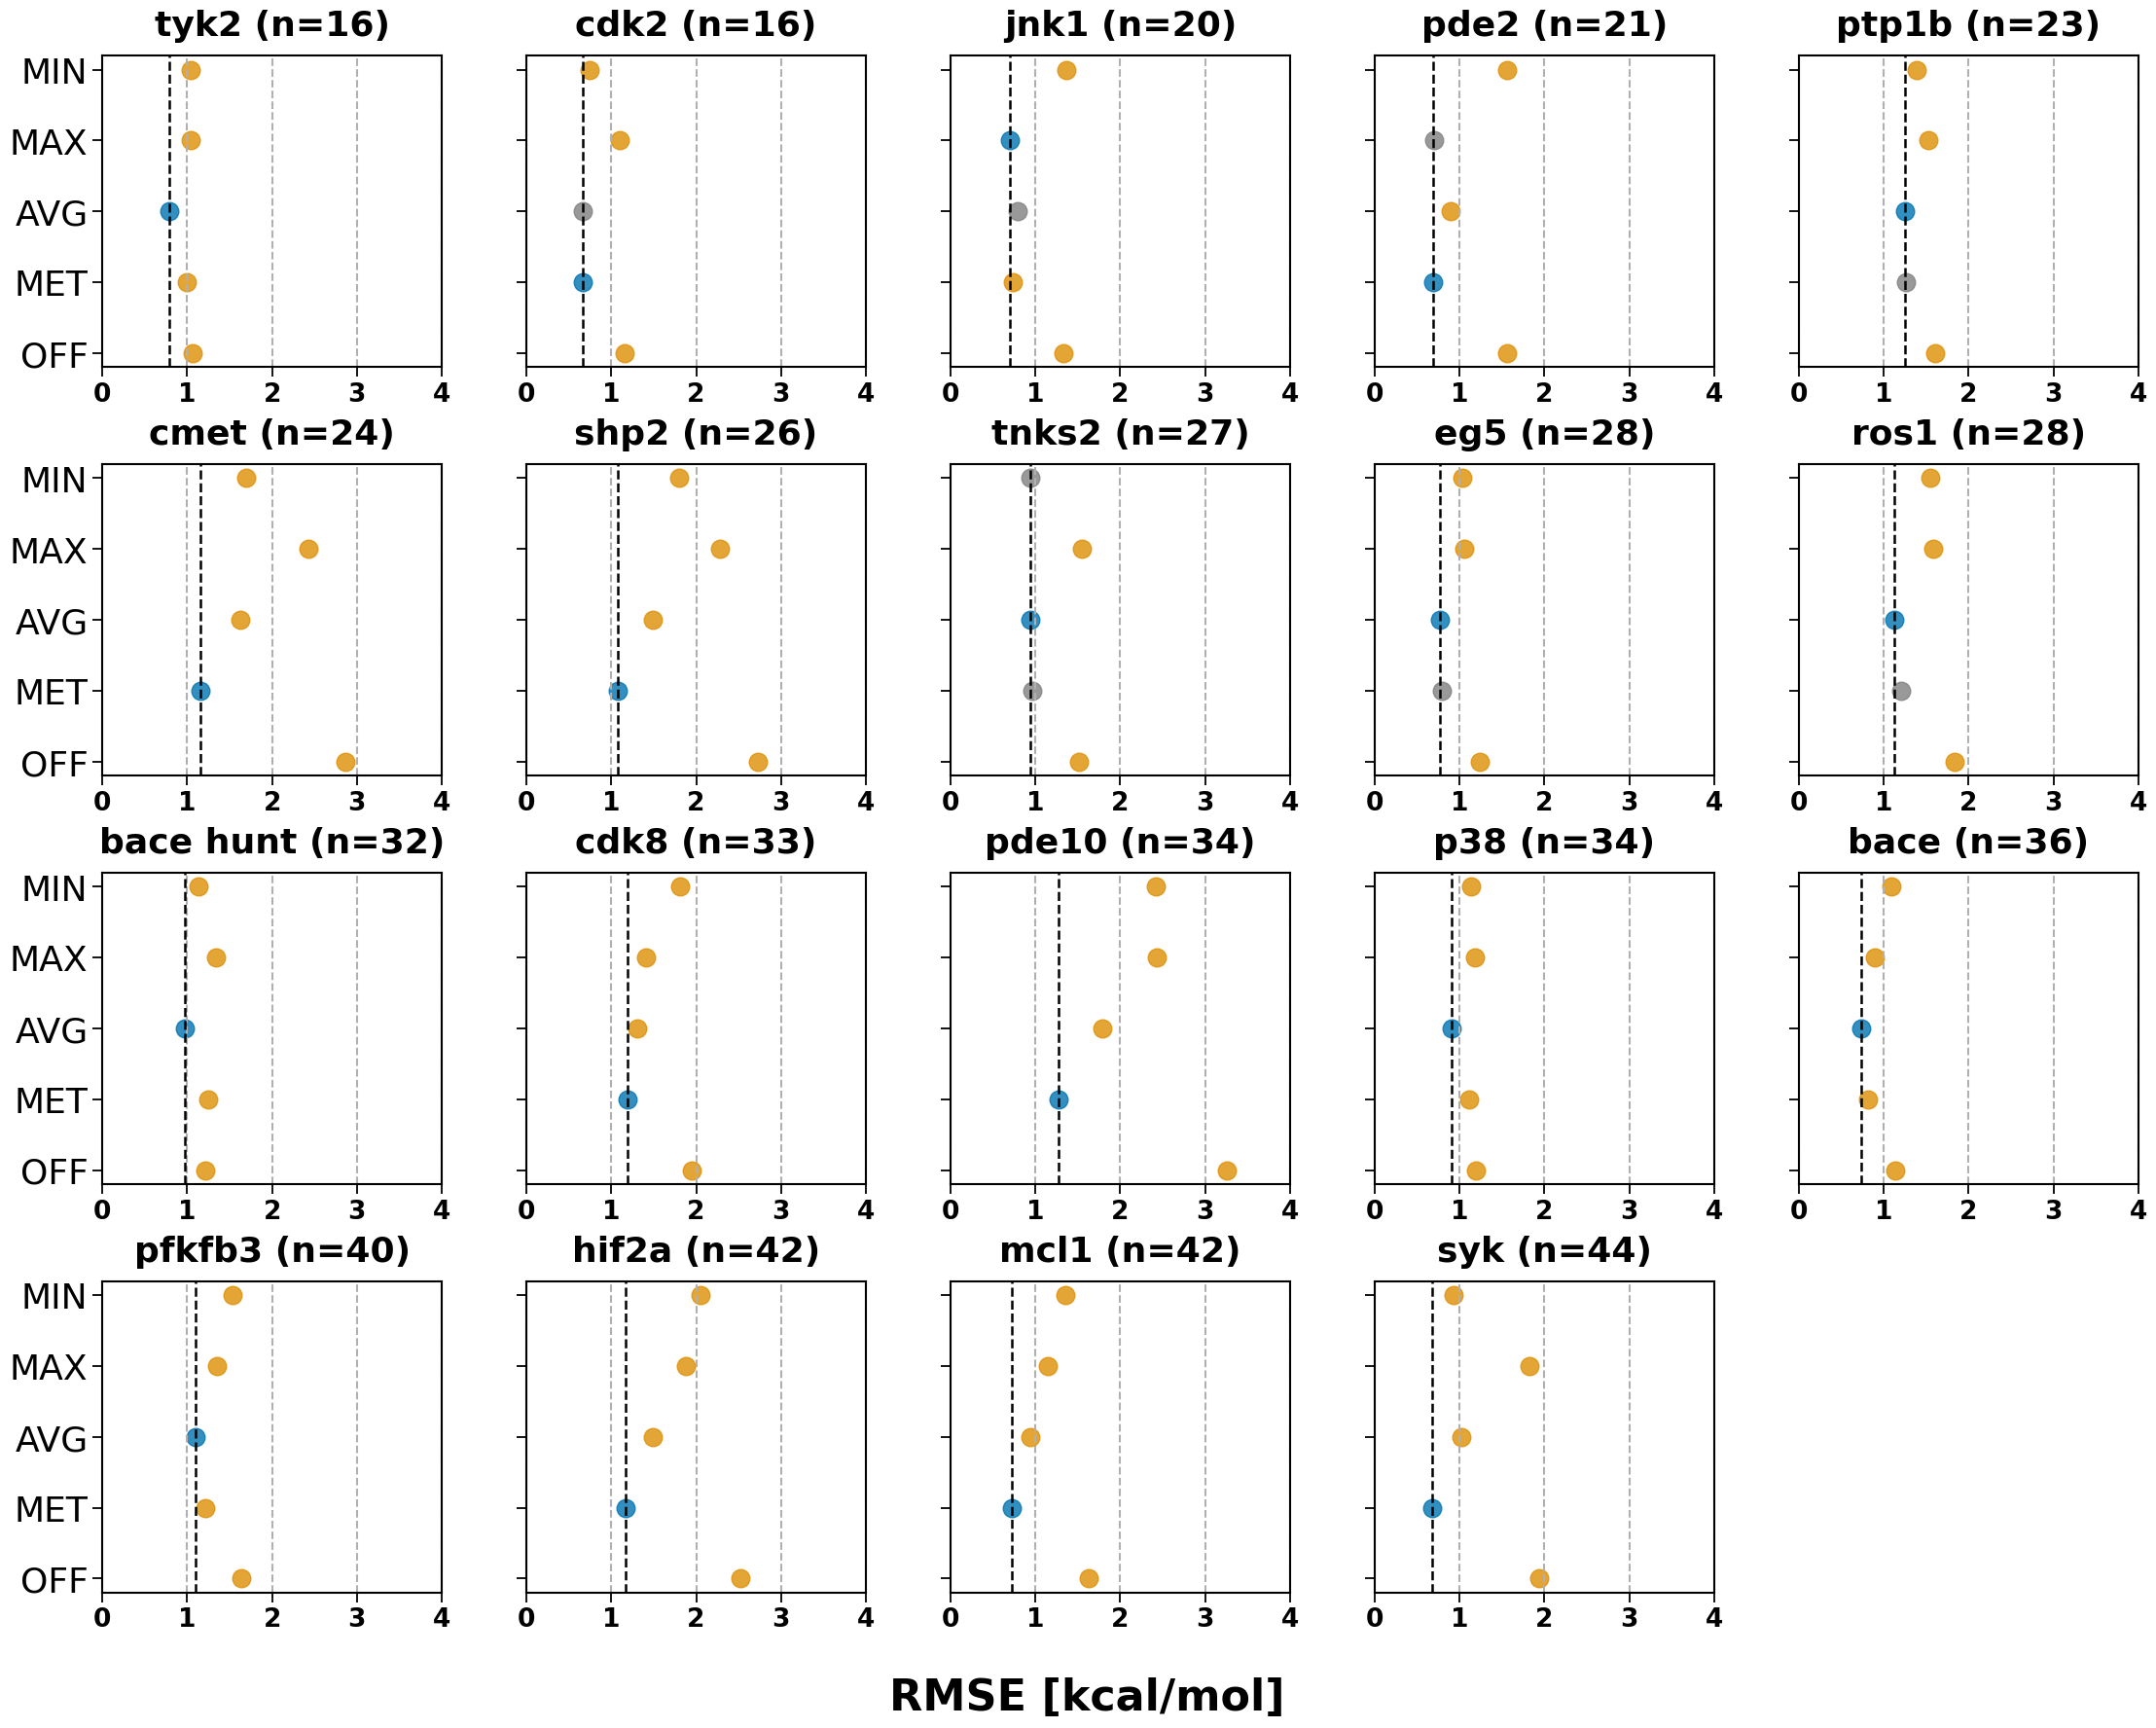


Effect-size counts for metric 'rmse':
- AVG: 5 targets → ['tnks2', 'eg5', 'ros1', 'bace', 'pfkfb3']
- MAX: 1 targets → ['jnk1']
- MET: 9 targets → ['cdk2', 'pde2', 'cmet', 'shp2', 'cdk8', 'pde10', 'hif2a', 'mcl1', 'syk']
- MIN: 0 targets → []
- OFF: 0 targets → []


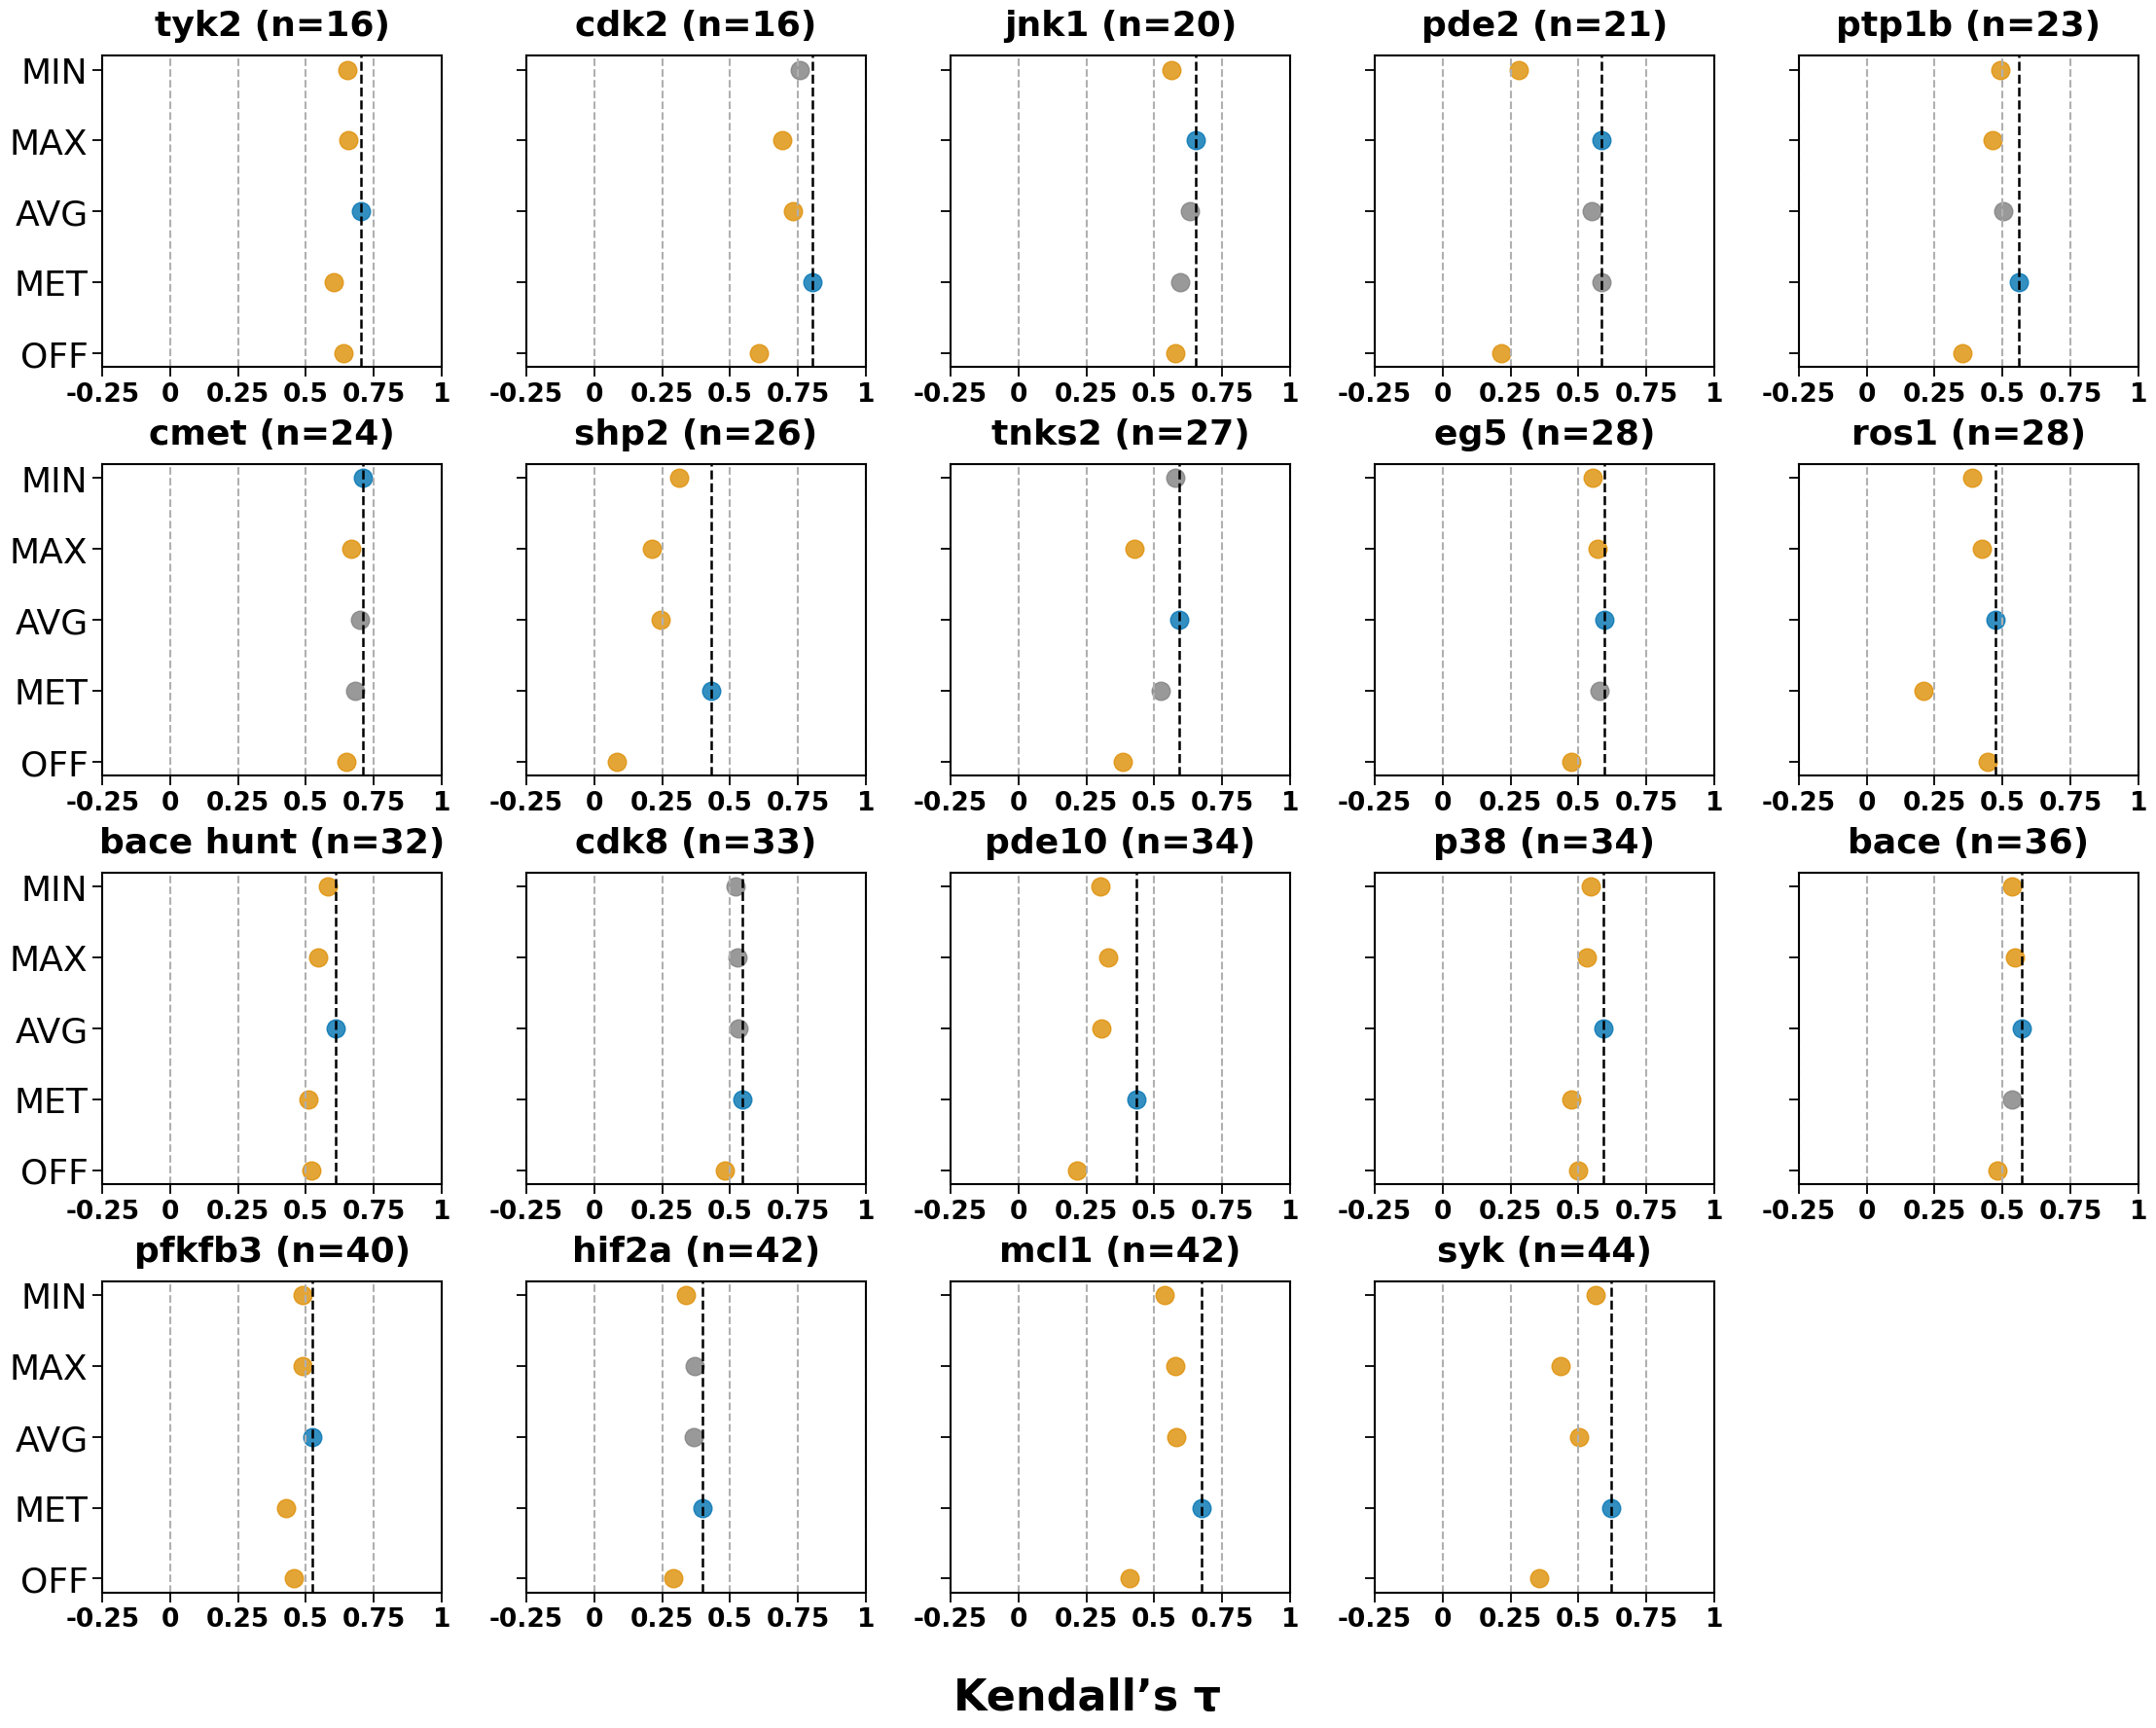


Effect-size counts for metric 'kendalls_tau':
- AVG: 2 targets → ['tnks2', 'ros1']
- MAX: 1 targets → ['pde2']
- MET: 5 targets → ['ptp1b', 'shp2', 'pde10', 'mcl1', 'syk']
- MIN: 0 targets → []
- OFF: 0 targets → []


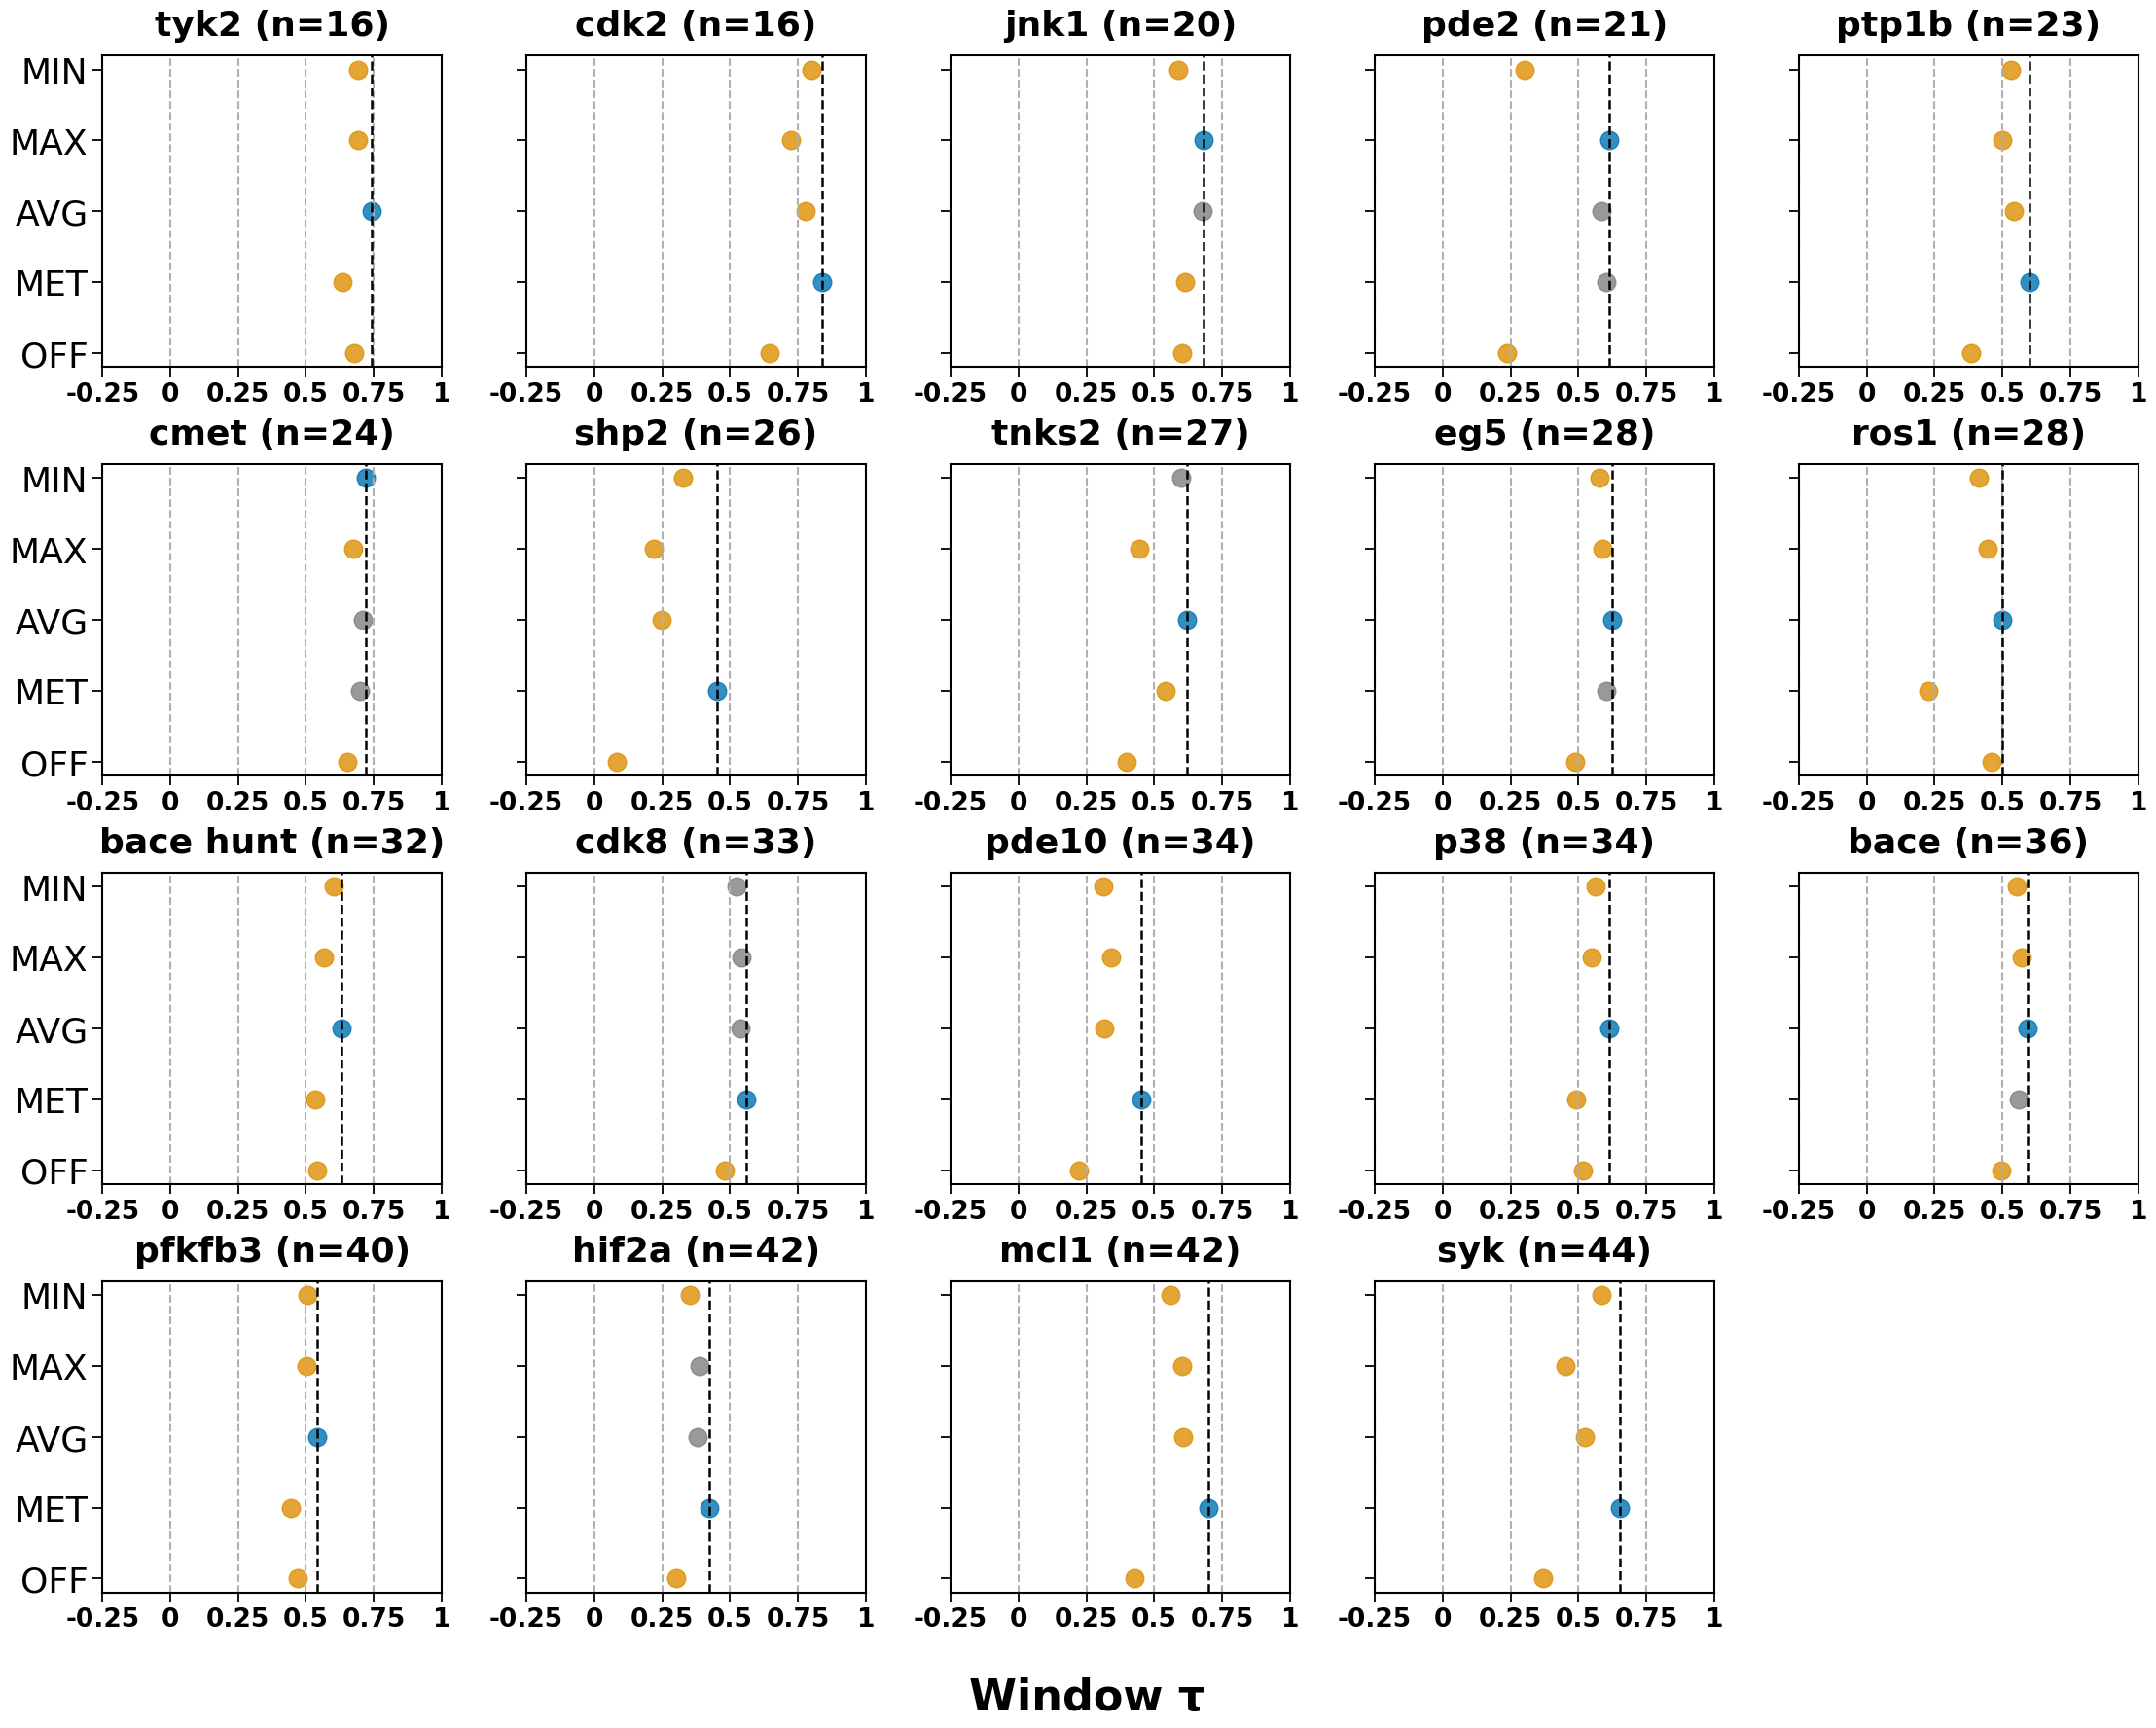


Effect-size counts for metric 'window_tau':
- AVG: 2 targets → ['tnks2', 'ros1']
- MAX: 1 targets → ['pde2']
- MET: 5 targets → ['ptp1b', 'shp2', 'pde10', 'mcl1', 'syk']
- MIN: 0 targets → []
- OFF: 0 targets → []


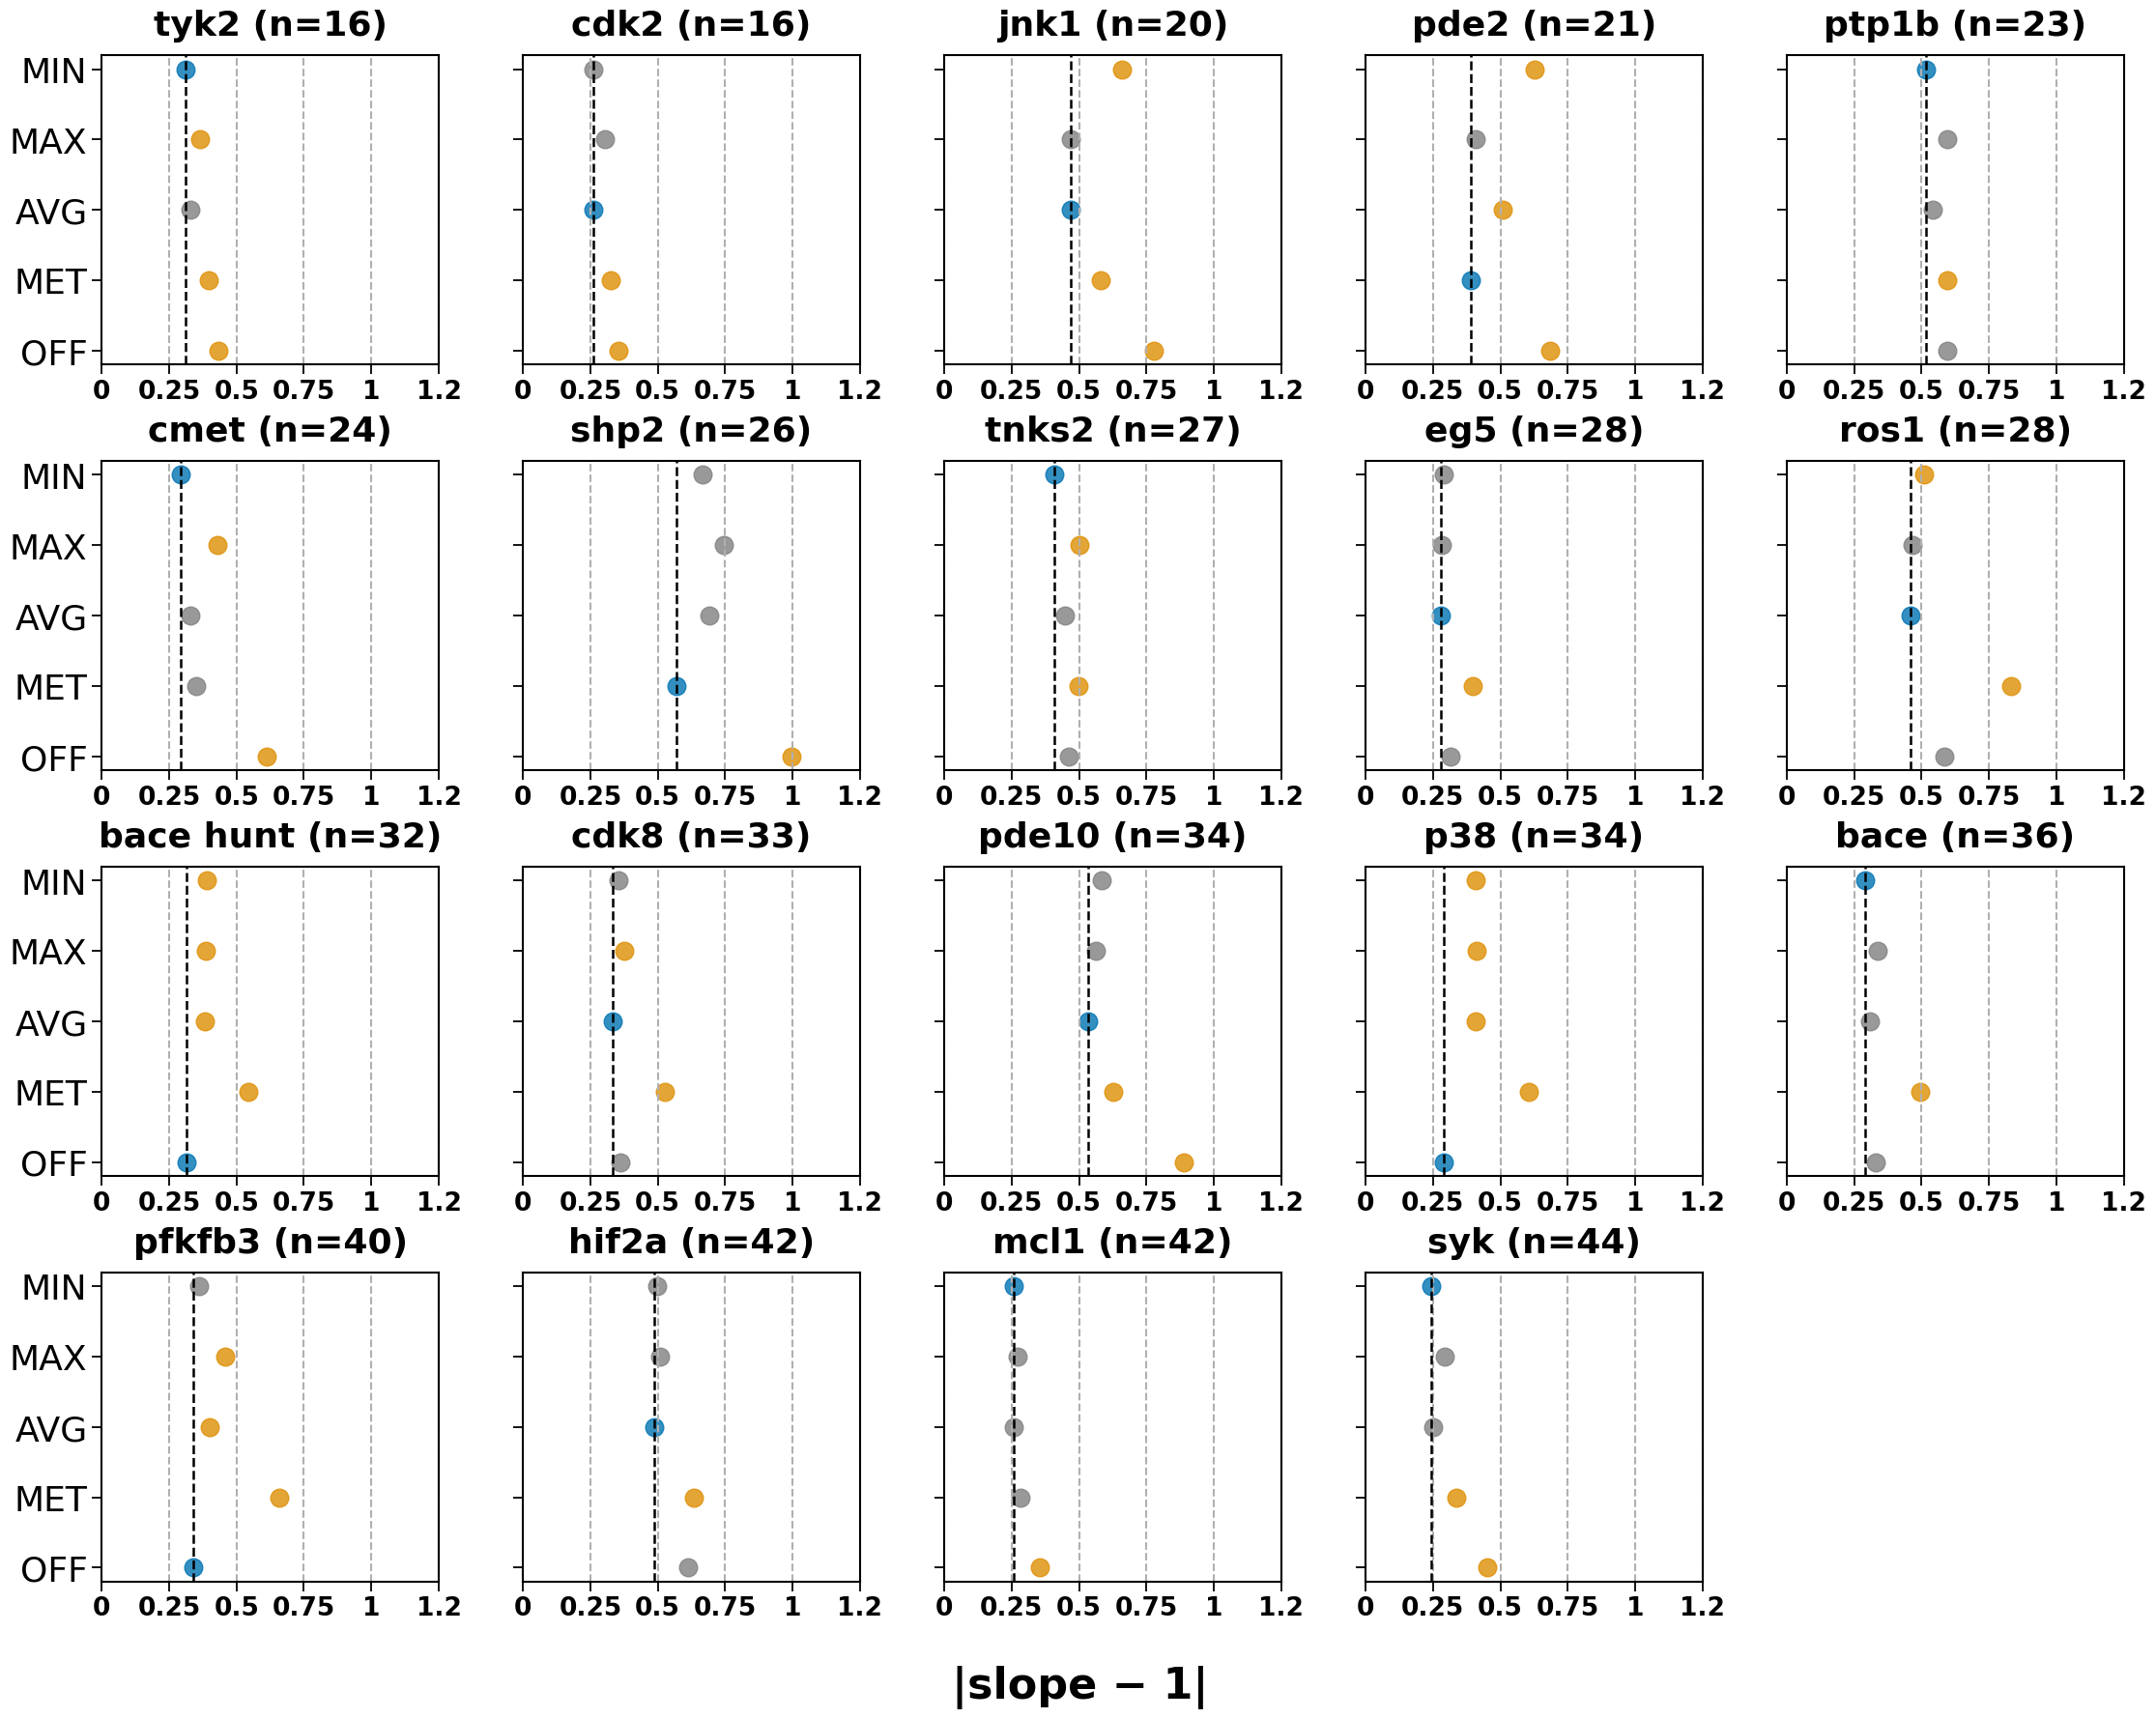


Effect-size counts for metric 'slope_diff':
- AVG: 3 targets → ['jnk1', 'ros1', 'pde10']
- MAX: 0 targets → []
- MET: 2 targets → ['pde2', 'shp2']
- MIN: 1 targets → ['cmet']
- OFF: 2 targets → ['p38', 'pfkfb3']


In [7]:
from DDG_ANALYSIS.E_EFFECT_SIZE_PLOT import plot_significance_ranks
plot_significance_ranks(results_all, DISPLAY_ORDER, ALPHA=ALPHA, METRICS=METRICS, target_counts_path="../../../0_DATA/N_COMPOUNDS_PER_TARGET.json", COUNT_EFFECTS=True, prefix="CONS_OFF_")